# Chapter 2. Literature Review

In [1]:
import os
import sys

from skimage import data
from skimage.color import rgb2gray
from skimage.util import img_as_float

# Add the project folder to Python path
sys.path.append("..")

from src.denoisers import anisotropic_denoise
from src.noise import add_gaussian_noise
from src.utils import show_images

# Set the output folder
plot_dir = "../results/plots"


## 2.1 Image Noise and Denoising

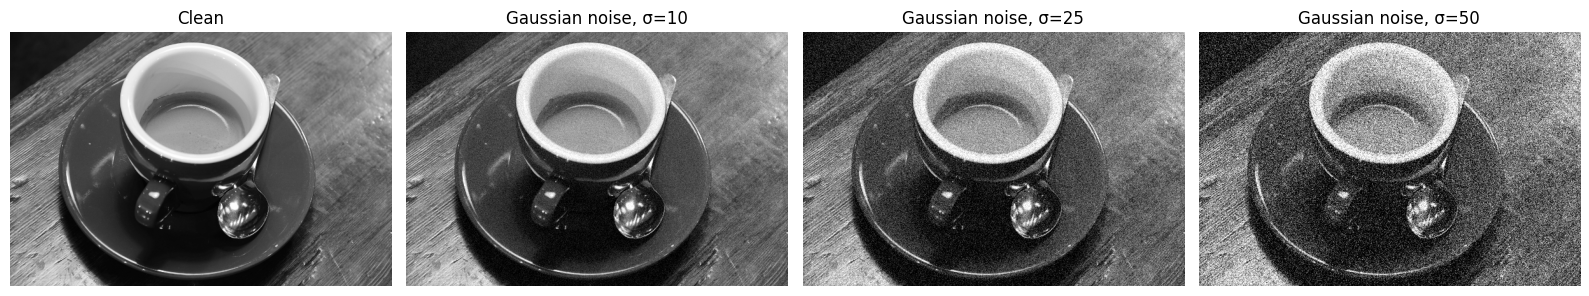

In [2]:
# Load a clean grayscale image
clean_image = img_as_float(rgb2gray(data.coffee()))

# Add Gaussian noise
noise_levels = [10, 25, 50]
noisy_images = []

for sigma in noise_levels:
    noisy_image = add_gaussian_noise(
        clean_image,
        sigma=sigma,
        seed=42
    )
    noisy_images.append(noisy_image)

# Show and save the comparison
images = [clean_image] + noisy_images
titles = ["Clean"] + [
    f"Gaussian noise, σ={sigma}"
    for sigma in noise_levels
]

show_images(
    images,
    titles,
    save_path=os.path.join(
        plot_dir,
        "gaussian_noise_levels.png"
    )
)


## 2.2 Edge-Preserving Denoising Methods

### 2.2.1 Anisotropic Diffusion

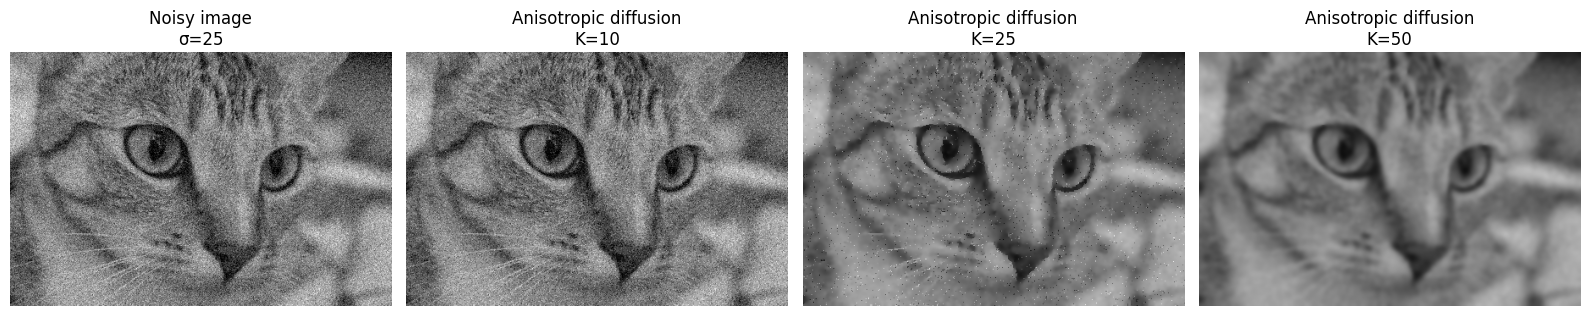

In [3]:
# Load a second grayscale image
clean_image = img_as_float(rgb2gray(data.cat()))

# Add Gaussian noise
sigma = 25
noisy_image = add_gaussian_noise(
    clean_image,
    sigma=sigma,
    seed=42
)

# Keep these settings fixed
n_iter = 20
gamma = 0.2
k_values = [10, 25, 50]

denoised_images = []

for k in k_values:
    # Convert K to the 0-1 image range
    denoised_image = anisotropic_denoise(
        noisy_image,
        n_iter=n_iter,
        kappa=k / 255.0,
        gamma=gamma,
        conduction="exponential"
    )
    denoised_images.append(denoised_image)

# Show and save the comparison
images = [noisy_image] + denoised_images
titles = [f"Noisy image\nσ={sigma}"] + [
    f"Anisotropic diffusion\nK={k}"
    for k in k_values
]

show_images(
    images,
    titles,
    save_path=os.path.join(
        plot_dir,
        "../results/plots/anisotropic_diffusion_k_comparison.png"
    )
)
